# Автоматическое дифференцирование <br>(Autograd)

**Что это такое?**
Это механизм, с помощью которого PyTorch **автоматически** <br>считает производные (градиенты) от любых операций над тензорами. Именно <br>благодаря ему нам не нужно вручную считать градиенты для параметров сети, <br>чтобы сделать шаг оптимизации. Pytorch берёт всю рутину на себя.

**В PyTorch:**
- **Вычислительный граф:** Последовательность операций над тензорами.
- **Autograd:** Запоминает все операции и считает производные.
- **Тензоры с `requires_grad=True`:** Переменные, для которых мы хотим узнать <br>влияние на результат.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('dark_background')

print(f"Версия PyTorch: {torch.__version__}")

Версия PyTorch: 2.12.0+cpu


## 1. Тензоры с `requires_grad=True`

Чтобы PyTorch начал отслеживать операции над тензором, нужно при его создании <br>(или позже) установить флаг `requires_grad = True`.

**Важно:** По умолчанию у тензоров этот флаг выключен — иначе PyTorch тратил бы <br>память на хранение графа для каждой переменной, даже для картинок и меток, <br>где градиенты не нужны.

In [2]:
# Создаём обычный тензор — autograd за ним НЕ следит
x_plain = torch.tensor(3.0)
print(f"Обычный тензор: requires_grad = {x_plain.requires_grad}")

# Создаём тензор с отслеживанием градиентов
x = torch.tensor(3.0, requires_grad=True)
print(f"Тензор с градиентом: requires_grad = {x.requires_grad}")
print(f"Тип данных (dtype): {x.dtype}")  # autograd работает только с float!

Обычный тензор: requires_grad = False
Тензор с градиентом: requires_grad = True
Тип данных (dtype): torch.float32


In [3]:
# Создаём тензор с целочисленными значениями с отслеживанием градиентов
try:
    x = torch.tensor(3, requires_grad=True)
except RuntimeError as e:
    print("❌ Ошибка:")
    print(str(e)[:150] + "...")

❌ Ошибка:
Only Tensors of floating point and complex dtype can require gradients...


## 2. Простейший пример: y = x²

Давайте посчитаем производную функции $y = x^2$ в точке $x = 3$.

Из математики мы знаем, что $\frac{dy}{dx} = 2x$, значит в точке $x = 3$ производная <br>равна $2 \cdot 3 = 6$.

Посмотрим, сможет ли PyTorch получить тот же ответ автоматически.

In [4]:
# 1. Создаём переменную x = 3 с отслеживанием градиента
x = torch.tensor(3.0, requires_grad=True)

# 2. Определяем функцию y = x^2
# PyTorch молча запоминает: "y получено из x через операцию возведения в квадрат"
y = x ** 2

print(f"x = {x.item()}")
print(f"y = {y.item()}")
print(f"\nФункция градиента (grad_fn): {y.grad_fn}")
print("\n💡 grad_fn показывает, КАКОЙ операцией был получен тензор.")
print("   Именно через неё autograd потом пойдёт назад по графу.")

x = 3.0
y = 9.0

Функция градиента (grad_fn): <PowBackward0 object at 0x0000022C0BF53F10>

💡 grad_fn показывает, КАКОЙ операцией был получен тензор.
   Именно через неё autograd потом пойдёт назад по графу.


In [5]:
# 3. Считаем градиент: вызываем backward()
# Это команда: "Пойди назад по графу и посчитай dy/dx
# для всех переменных с requires_grad=True"
y.backward()

# 4. Градиент сохранился в атрибуте .grad исходного тензора x
print(f"Градиент dy/dx в точке x=3: {x.grad.item()}")
print(f"Ожидали (2*x): {2 * x}")
if x.grad == 2*x:
    print("\n✅ Совпадает! Autograd работает.")

Градиент dy/dx в точке x=3: 6.0
Ожидали (2*x): 6.0

✅ Совпадает! Autograd работает.


## 3. Цепочка операций (Вычислительный граф)

В реальных нейросетях функция редко бывает просто $x^2$. Обычно это длинная <br>цепочка операций.

Рассмотрим: $z = (x + 1)^2$

Раскроем по шагам:
1. $a = x + 1$
2. $z = a^2$

По правилу цепочки (chain rule): $\frac{dz}{dx} = \frac{dz}{da} \cdot \frac{da}{dx} = 2a \cdot 1 = 2(x + 1)$

В точке $x = 2$: $\frac{dz}{dx} = 2 \cdot (2 + 1) = 6$

In [6]:
x = torch.tensor(2.0, requires_grad=True)

# Строим граф вычислений
a = x + 1          # grad_fn = <AddBackward0>
z = a ** 2         # grad_fn = <PowBackward0>

print(f"x = {x.item()}")
print(f"a = x + 1 = {a.item()}, grad_fn = {a.grad_fn}")
print(f"z = a^2   = {z.item()}, grad_fn = {z.grad_fn}")

# Считаем градиент
z.backward()

print(f"\nГрадиент dz/dx: {x.grad.item()}")
print(f"Ожидали (2*(x+1)): {2 * (x + 1)}")

x = 2.0
a = x + 1 = 3.0, grad_fn = <AddBackward0 object at 0x0000022C1BF67D90>
z = a^2   = 9.0, grad_fn = <PowBackward0 object at 0x0000022C1BF67CA0>

Градиент dz/dx: 6.0
Ожидали (2*(x+1)): 6.0


In [10]:
print(f"\nГрадиент dz/da: {a.grad}")



Градиент dz/da: None


C:\Users\Sergey\AppData\Local\Temp\ipykernel_3592\2093974733.py:1: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more information. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\build\aten\src\ATen/core/TensorBody.h:499.)
  print(f"\nГрадиент dz/da: {a.grad}")


In [11]:
x = torch.tensor(2.0, requires_grad=True)

# Строим граф операций
a = x + 1          # grad_fn = <AddBackward0>
z = a ** 2         # grad_fn = <PowBackward0>

print(f"x = {x.item()}")
print(f"a = x + 1 = {a.item()}, grad_fn = {a.grad_fn}")
print(f"z = a^2   = {z.item()}, grad_fn = {z.grad_fn}")

a.retain_grad()
z.retain_grad()

# Считаем градиент
z.backward()

print(f"\nГрадиент dz/dz:     {z.grad.item()}")
print(f"Градиент dz/da:     {a.grad.item()}")
print(f"Градиент dz/dx:     {x.grad.item()}")
print(f"Ожидали  (2*(x+1)): {2 * (x + 1)}")

x = 2.0
a = x + 1 = 3.0, grad_fn = <AddBackward0 object at 0x0000022C1BF67C10>
z = a^2   = 9.0, grad_fn = <PowBackward0 object at 0x0000022C0BF53310>

Градиент dz/dz:     1.0
Градиент dz/da:     6.0
Градиент dz/dx:     6.0
Ожидали  (2*(x+1)): 6.0


## 4. Многомерные тензоры и градиенты

В реальных задачах $x$ — это не одно число, а вектор весов, или матрица, или <br>многомерный тензор. Посмотрим, как autograd работает с векторами.

Пусть $\mathbf{x} = [1, 2, 3]$, а мы считаем $y = \sum x_i^2 = x_1^2 + x_2^2 + x_3^2$.

Градиент — это вектор частных производных:

$\nabla y = \left[\frac{\partial y}{\partial x_1}, \frac{\partial y}{\partial x_2}, \frac{\partial y}{\partial x_3}\right] = [2x_1, 2x_2, 2x_3] = [2, 4, 6]$

In [17]:
x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)

# y = x^2 (поэлементно), затем sum — чтобы получить скаляр
y = (x ** 2).sum()

print(f"x = {x}")
print(f"y = sum(x^2) = {y.item()}")

y.backward()

print(f"\nГрадиент ∇y = {x.grad}")
dx1 = 2*x[0]
dx2 = 2*x[1]
dx3 = 2*x[2]
print(f"Ожидали:      tensor([{dx1}, {dx2}, {dx3}])")

x = tensor([1., 2., 3.], requires_grad=True)
y = sum(x^2) = 14.0

Градиент ∇y = tensor([2., 4., 6.])
Ожидали:      tensor([2.0, 4.0, 6.0])


### ⚠️ Почему `backward()` работает только со скалярами?

Если `y` — это вектор, а не скаляр, PyTorch не знает, какую именно производную <br>считать. Поэтому нужно либо:
1. Свернуть `y` в скаляр (через `.sum()`, `.mean()`)
2. Передать в `backward()` аргумент `gradient` — вектор той же формы, что и `y`.

В нейросетях почти всегда `y` — это скаляр (функция потерь `loss`), поэтому эта <br>тонкость возникает редко.

In [18]:
# Попробуем вызвать backward() для вектора — получим ошибку
x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
y = x ** 2  # это вектор, не скаляр!

try:
    y.backward()  # ❌ Ошибка!
except RuntimeError as e:
    print("❌ Ошибка:")
    print(str(e)[:150] + "...")

print("\n✅ Решение — передать вектор весов:")
y.backward(torch.tensor([1.0, 1.0, 1.0]))  # это эквивалентно sum(y)
print(f"Градиент: {x.grad}")

❌ Ошибка:
grad can be implicitly created only for scalar outputs...

✅ Решение — передать вектор весов:
Градиент: tensor([2., 4., 6.])


## 5. Отключение отслеживания градиентов

Иногда нам нужно **остановить** autograd. Например:
- При валидации/тестировании модели (нам не нужны градиенты — только предсказания).
- Когда мы "замораживаем" часть модели (Transfer Learning).
- Чтобы ускорить вычисления и сэкономить память.

Есть 3 основных способов:

In [32]:
x = torch.tensor(5.0, requires_grad=True)
z = torch.tensor(10.0, requires_grad=True)

# === Способ 1: torch.no_grad() ===
# Контекстный менеджер — отключает autograd внутри блока
with torch.no_grad():
    y = x * 2
    print("Внутри 'with torch.no_grad()'")
    print(f"no_grad: x.requires_grad = {x.requires_grad}")  # True
    print(f"no_grad: y.requires_grad = {y.requires_grad}")  # False

    try:
        print("Метод 'backward':")
        y.backward()
        print("    ✅ Метод 'backward' отработал без ошибок")
    except RuntimeError as e:
        print("    ❌ Ошибка:", str(e)[:150] + "...")

a = z * y
print("\nВне 'with torch.no_grad()'")
print(f"no_grad: a.requires_grad = {a.requires_grad}")  # True
print(f"no_grad: y.requires_grad = {y.requires_grad}")  # False

try:
    print("Метод 'backward':")
    a.backward()
    print("    ✅ Метод 'backward' отработал без ошибок")
except RuntimeError as e:
        print("    ❌ Ошибка:", str(e)[:150] + "...")

print("\nПосчитанные градиенты:")
print("    Градиенты X:", x.grad)
print("    Градиенты Y:", y.grad)
print("    Градиенты Z:", z.grad)
print("    Градиенты A:", a.grad)


Внутри 'with torch.no_grad()'
no_grad: x.requires_grad = True
no_grad: y.requires_grad = False
Метод 'backward':
    ❌ Ошибка: element 0 of tensors does not require grad and does not have a grad_fn...

Вне 'with torch.no_grad()'
no_grad: a.requires_grad = True
no_grad: y.requires_grad = False
Метод 'backward':
    ✅ Метод 'backward' отработал без ошибок

Посчитанные градиенты:
    Градиенты X: None
    Градиенты Y: None
    Градиенты Z: tensor(10.)
    Градиенты A: None


C:\Users\Sergey\AppData\Local\Temp\ipykernel_18704\2951516124.py:35: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more information. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\build\aten\src\ATen/core/TensorBody.h:499.)
  print("    Градиенты A:", a.grad)


In [33]:
# === Способ 2: .detach() ===
# Создаёт копию тензора, "отклеенную" от графа
z = x.detach()
print(f"detach: z.requires_grad = {z.requires_grad}")  # False
print(f"Но сам x по-прежнему требует градиент: {x.requires_grad}")  # True


detach: z.requires_grad = False
Но сам x по-прежнему требует градиент: True


In [34]:
# === Способ 3: @torch.no_grad() декоратор ===
@torch.no_grad()
def evaluate_model(x):
    return x ** 2

w = evaluate_model(x)
print(f"@no_grad: w.requires_grad = {w.requires_grad}")  # False

@no_grad: w.requires_grad = False


In [35]:
z = torch.tensor(10.0, requires_grad=True)

# === torch.inference_mode() ===
# Контекстный менеджер для валидации и тестирования
with torch.inference_mode():
    y = x * 2
    print("Внутри 'torch.inference_mode()'")
    print(f"no_grad: y.requires_grad = {y.requires_grad}")  # False

    try:
        y.backward()
        print("✅ Метод 'backward' отработал без ошибок")
    except RuntimeError as e:
        print("❌ Ошибка:", str(e)[:150] + "...")


try:
    a = z * y
except RuntimeError as e:
        print("\n❌ Ошибка:", str(e)[:100] + "...")

Внутри 'torch.inference_mode()'
no_grad: y.requires_grad = False
❌ Ошибка: element 0 of tensors does not require grad and does not have a grad_fn...

❌ Ошибка: Inference tensors cannot be saved for backward. Please do not use Tensors created in inference mode ...


## 6. 🚨 Градиенты НАКАПЛИВАЮТСЯ!

Это **частая ошибка новичков**. По умолчанию PyTorch **суммирует** <br>новые градиенты со старыми в `.grad`.

**Зачем так сделано?** Это полезно для некоторых техник (например, RNN, <br>накопление градиентов при малой GPU-памяти). Но в обычном обучении <br>это приводит к багам!

**Решение:** Перед каждым `backward()` нужно обнулять градиенты <br>через `optimizer.zero_grad()` или `x.grad.zero_()`.

In [37]:
x = torch.tensor(3.0, requires_grad=True)

# Первый backward
y = x ** 2
y.backward()
print(f"После 1-го backward: x.grad = {x.grad.item()}")  # 6.0

# Второй backward — БЕЗ обнуления!
y = x ** 2
y.backward()
print(f"После 2-го backward: x.grad = {x.grad.item()}")  # 12.0 = 6 + 6 ❌

# Третий backward — С обнулением ✅
x.grad.zero_()  # Обнуляем градиент
y = x ** 2
y.backward()
print(f"После 3-го backward (с zero_): x.grad = {x.grad.item()}")  # 6.0 ✅

После 1-го backward: x.grad = 6.0
После 2-го backward: x.grad = 12.0
После 3-го backward (с zero_): x.grad = 6.0


## 7. Практика: Градиентный спуск вручную

Теперь соберём всё вместе и решим настоящую задачу — **линейную регрессию** <br>$y = wx + b$ с помощью градиентного спуска, **не используя** готовые <br>оптимизаторы PyTorch.

Это поможет понять, что происходит "под капотом" у `torch.optim.SGD`.

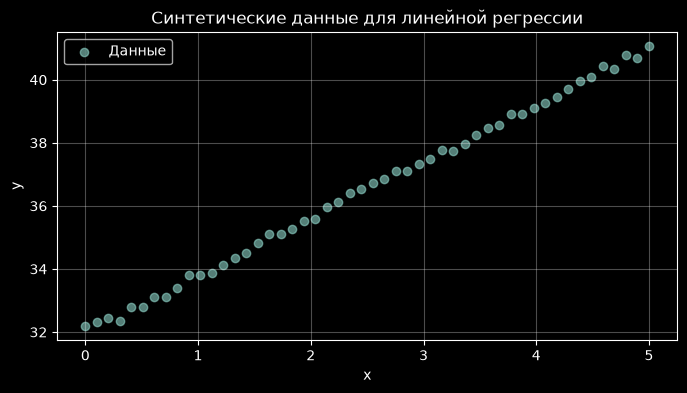

In [26]:
# Генерируем синтетические данные: y = 2x + 1 + шум
torch.manual_seed(42)
X = torch.linspace(0, 5, 50).reshape(-1, 1)  # 50 точек
W_real = 1.8
B_real = 32
y_true = W_real * X + B_real + 0.1 * torch.randn_like(X)  # шум

plt.figure(figsize=(8, 4))
plt.scatter(X.numpy(), y_true.numpy(), alpha=0.6, label='Данные')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Синтетические данные для линейной регрессии')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [36]:
# Инициализируем веса СЛУЧАЙНЫМИ значениями
w = torch.tensor(0.0, requires_grad=True)
b = torch.tensor(0.0, requires_grad=True)

lr = 0.1  # learning rate — скорость обучения
num_epochs = 200

loss_history = []

for epoch in range(num_epochs):
    # 1. Forward pass: считаем предсказания
    y_pred = w * X + b

    # 2. Считаем функцию потерь (MSE — Mean Squared Error)
    loss = ((y_pred - y_true) ** 2).mean()

    # 3. Backward pass: считаем градиенты
    loss.backward()

    # 4. Обновляем веса В РУЧНУЮ по формуле градиентного спуска:
    #    w_new = w_old - lr * (dL/dw)
    #    b_new = b_old - lr * (dL/db)
    with torch.no_grad():  # ❗ Важно: обновление весов НЕ должно попадать в граф!
        w -= lr * w.grad
        b -= lr * b.grad

        # 5. Обнуляем градиенты! (иначе будут накапливаться)
        w.grad.zero_()
        b.grad.zero_()

    loss_history.append(loss.item())

    if (epoch + 1) % 40 == 0:
        print(f"Эпоха {epoch+1:3d}",
              f"Loss: {loss.item():8.4f}",
              f"w: {w.item():.3f}",
              f"b: {b.item():.3f}", sep=" | ")

print(f"\n✅ Итоговые веса:        w = {w.item():.3f}, b = {b.item():.3f}")
print(f"🎯 Ожидали (из формулы): w ≈ {W_real},   b ≈ {B_real}")

Эпоха  40 | Loss:   4.9217 | w: 3.060 | b: 27.854
Эпоха  80 | Loss:   0.1131 | w: 1.982 | b: 31.412
Эпоха 120 | Loss:   0.0129 | w: 1.826 | b: 31.925
Эпоха 160 | Loss:   0.0108 | w: 1.803 | b: 31.999
Эпоха 200 | Loss:   0.0108 | w: 1.800 | b: 32.010

✅ Итоговые веса:        w = 1.800, b = 32.010
🎯 Ожидали (из формулы): w ≈ 1.8,   b ≈ 32


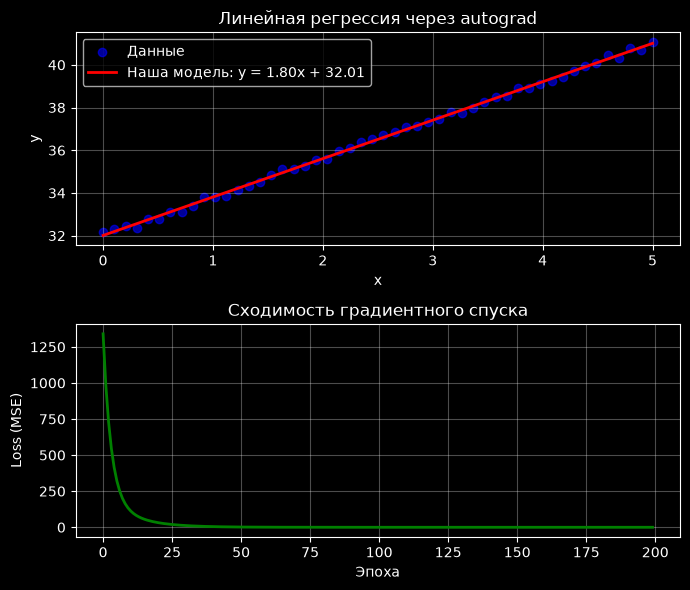

In [ ]:
# Визуализируем результат
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 6))

# Верхний график: данные и полученная модель
ax1.scatter(X.numpy(), y_true.numpy(), alpha=0.6, label='Данные', color='blue')
x_line = torch.linspace(0, 5, 50)
y_line = w.item() * x_line + b.item()
ax1.plot(x_line.numpy(), y_line.numpy(), color='red', linewidth=2,
         label=f'Наша модель: y = {w.item():.2f}x + {b.item():.2f}')
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_title('Линейная регрессия через autograd')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Правый график: сходимость loss
ax2.plot(loss_history, color='green', linewidth=2)
ax2.set_xlabel('Эпоха')
ax2.set_ylabel('Loss (MSE)')
ax2.set_title('Сходимость градиентного спуска')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Что происходит "под капотом" <br>у оптимизаторов?

Теперь вы понимаете, что `torch.optim.SGD` делает ровно то же самое, что мы <br>написали вручную:

```python
# optimizer.zero_grad()  →  w.grad.zero_(); b.grad.zero_()
# loss.backward()        →  считаем градиенты через autograd
# optimizer.step()       →  w -= lr * w.grad; b -= lr * b.grad
```

Разница только в том, что оптимизатор делает это **для всех параметров модели сразу** <br>и поддерживает более сложные алгоритмы (AdamW, RMSProp и т.д.).

## Итоги видео:

1. **Autograd** — это движок PyTorch для автоматического подсчёта градиентов. <br>Он строит вычислительный граф во время forward pass и проходит по нему <br>назад при `backward()`.

2. Чтобы тензор попал в граф, у него должен быть `requires_grad=True` <br>(или он должен быть получен из такого тензора).

3. Градиент сохраняется в атрибуте `.grad` исходного тензора (leaf tensor).

4. **`backward()` работает только со скалярами.** Для векторов нужно либо <br>сворачивать их (`.sum()`), либо передавать аргумент `gradient`.

5. **Градиенты накапливаются!** Всегда вызывайте `optimizer.zero_grad()` <br>или `x.grad.zero_()` перед `backward()`.

6. Обновление весов нужно оборачивать в `with torch.no_grad():`, чтобы оно <br>не попало в вычислительный граф (оптимизаторы делают это самостоятельно).

7. Три способа отключить autograd: `torch.no_grad()`, `.detach()`, `@torch.no_grad()`.

## 📚 Домашнее задание:

Реализуйте градиентный спуск **с нуля** (без `torch.nn` и `torch.optim`) для <br>**полиномиальной регрессии**:

$y = w_2 x^2 + w_1 x + w_0$

**Шаги:**
1. Сгенерируйте данные по формуле $y = 1.7x^2 - 9x + 5 + \text{шум}$.
2. Инициализируйте три веса $w_0, w_1, w_2$ с `requires_grad=True`.
3. Напишите цикл обучения: forward → loss → backward → update weights → zero_grad.
4. Выведите итоговые веса и сравните с истинными.
5. Постройте график: данные + полиномиальная кривая + график сходимости loss.

**Подсказка:** Формула предсказания: `y_pred = w2 * X**2 + w1 * X + w0`

**Бонус (со звёздочкой ⭐):** Попробуйте разные learning rate (0.001, 0.01, 0.1, 1.0) <br>и посмотрите, как это влияет на сходимость. При каком LR обучение "разваливается"?